# 5.1 Estimation quality on the reference dataset

Here we use only test subset and results estimated earlier in the notebook #4.1.

In [1]:
import os
import pandas as pd
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

from common.configuration import DatasetPath, species_classes_map_all, species_by_familia, species_by_ordo, species_invasive

Load dataset and replace invasive labels with "Unknown", which is an estimated response.

In [2]:
predictions_path = "Save/reference_predictions.csv"
model_prediction_df = pd.read_csv(predictions_path, index_col=0).fillna(0)
model_prediction_df["label"] = model_prediction_df["label"].map(lambda x: "Unknown" if x in species_invasive else x)
model_prediction_df


,label,prediction,embeddings,image
0,Acer,Unknown,[ 1.7415385 0.3334825 -0.03600454 -0.572933...,Dataset/pollen_dataset_2025_02_05\samples/Acer...
1,Acer,Ulmus,[ 1.5100751 -0.15566942 0.4809177 0.910175...,Dataset/pollen_dataset_2025_02_05\samples/Acer...
2,Acer,Unknown,[ 3.7482874 -0.74534714 -0.34647214 0.586683...,Dataset/pollen_dataset_2025_02_05\samples/Acer...
3,Acer,Unknown,[ 2.1391215 0.364511 0.16875696 2.004651...,Dataset/pollen_dataset_2025_02_05\samples/Acer...
4,Acer,Acer,[ 6.2565627 0.39929396 -0.13376594 -0.538832...,Dataset/pollen_dataset_2025_02_05\samples/Acer...
...,...,...,...,...
764,Unknown,Salix,[ 4.044817 0.94807583 -0.43934408 -0.880034...,Dataset/pollen_dataset_2025_02_05\samples/Malu...
765,Unknown,Acer,[ 4.663302 -0.58977324 -0.06809011 -0.463438...,Dataset/pollen_dataset_2025_02_05\samples/Malu...
766,Unknown,Acer,[ 3.9824102 1.8363025 0.7037991 -0.816554...,Dataset/pollen_dataset_2025_02_05\samples/Malu...
767,Unknown,Salix,[ 5.4909763e+00 -1.2012720e-03 -1.2081781e-01 ...,Dataset/pollen_dataset_2025_02_05\samples/Malu...


## Quality on Genus level

In [3]:
possible_labels = list(set(pd.unique(model_prediction_df["label"])) | set(pd.unique(model_prediction_df["prediction"])))
possible_labels.sort()
possible_labels.append(possible_labels.pop(possible_labels.index("Unknown")))
possible_labels

['Acer',
 'Alnus',
 'Ambrosia',
 'Apiaceae',
 'Artemisia',
 'Betula',
 'Chenopodiaceae',
 'Corylus',
 'Picea',
 'Pinus',
 'Plantago',
 'Poaceae',
 'Populus tremula',
 'Quercus',
 'Rumex',
 'Salix',
 'Tilia',
 'Ulmus',
 'Urtica',
 'Unknown']

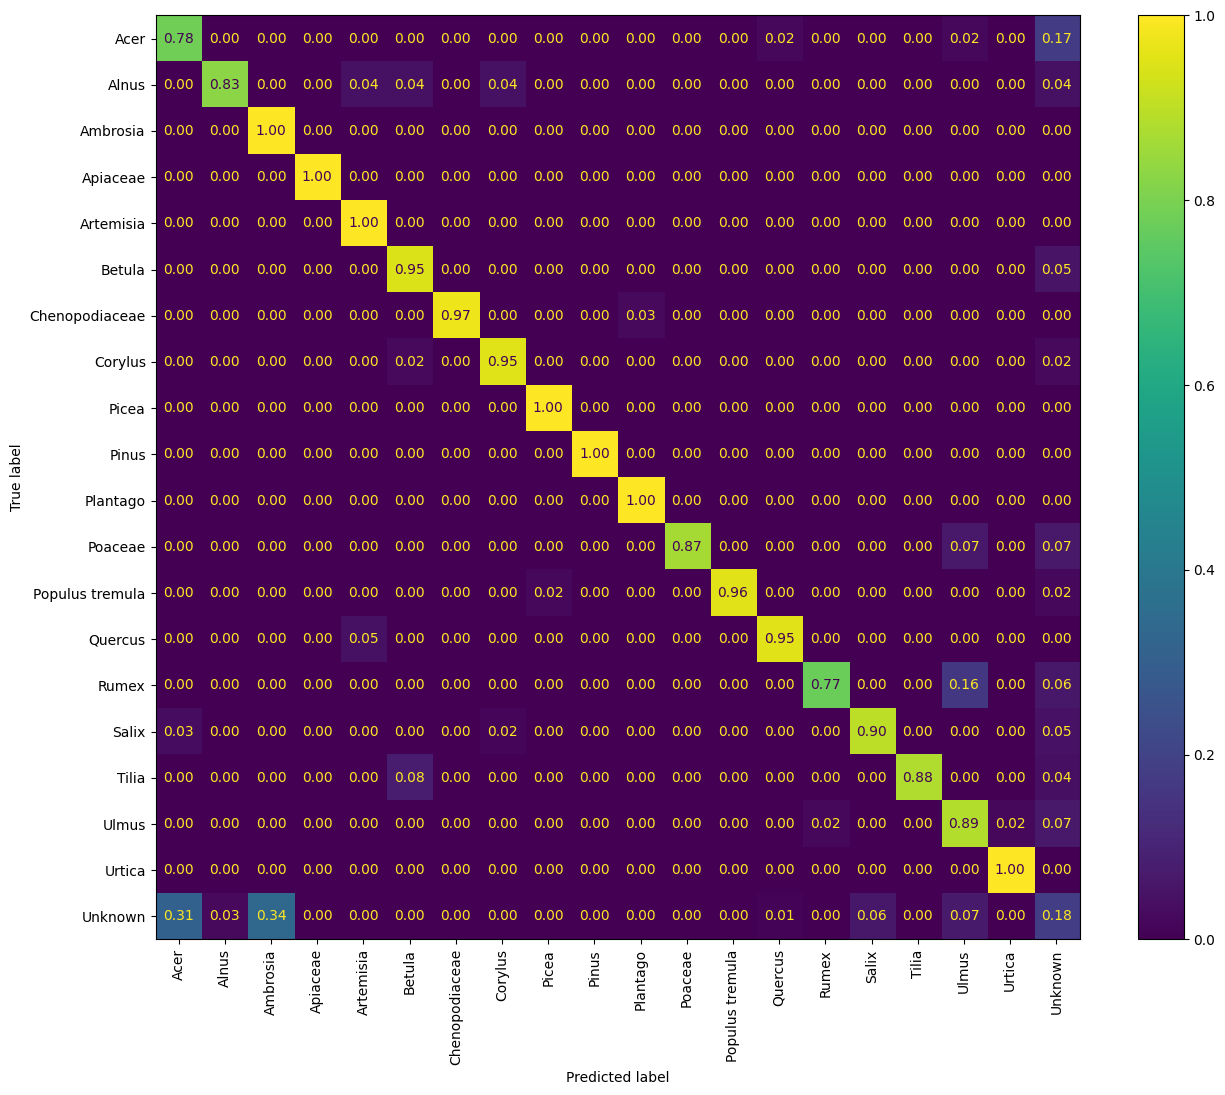

In [4]:
fig, ax = plt.subplots(figsize=(15,12))
cm = confusion_matrix(model_prediction_df["label"], model_prediction_df["prediction"], labels=possible_labels)
disp = ConfusionMatrixDisplay.from_predictions(
    model_prediction_df["label"], 
    model_prediction_df["prediction"], 
    labels=possible_labels, 
    display_labels=possible_labels,
    xticks_rotation="vertical",
    normalize="true",
    values_format=".2f",
    ax=ax)
plt.savefig("Save/images/confusion_matrix_reference_ds.svg")

In [5]:
print(classification_report(model_prediction_df["label"], model_prediction_df["prediction"], labels=possible_labels))

                 precision    recall  f1-score   support

           Acer       0.50      0.78      0.61        46
          Alnus       0.86      0.83      0.84        23
       Ambrosia       0.44      1.00      0.61        29
       Apiaceae       1.00      1.00      1.00        34
      Artemisia       0.96      1.00      0.98        45
         Betula       0.93      0.95      0.94        56
 Chenopodiaceae       1.00      0.97      0.99        38
        Corylus       0.95      0.95      0.95        41
          Picea       0.96      1.00      0.98        22
          Pinus       1.00      1.00      1.00        17
       Plantago       0.91      1.00      0.95        10
        Poaceae       1.00      0.87      0.93        15
Populus tremula       1.00      0.96      0.98        45
        Quercus       0.91      0.95      0.93        22
          Rumex       0.96      0.77      0.86        31
          Salix       0.89      0.90      0.89        61
          Tilia       1.00    

## Quality on Family level

Firstly we need to add collumn with label and predicted familia.

In [6]:
label_to_familia = { v: k for k, l in species_by_familia.items() for v in l }
label_to_familia["Unknown"] = "Unknown"
label_to_familia

{'Acer': 'Sapindaceae',
 'Alnus': 'Betulaceae',
 'Betula': 'Betulaceae',
 'Corylus': 'Betulaceae',
 'Ulmus': 'Ulmaceae',
 'Quercus': 'Fagaceae',
 'Salix': 'Salicaceae',
 'Populus tremula': 'Salicaceae',
 'Tilia': 'Malvaceae',
 'Pinus': 'Pinaceae',
 'Picea': 'Pinaceae',
 'Apiaceae': 'Apiaceae',
 'Artemisia': 'Asteraceae',
 'Ambrosia': 'Asteraceae',
 'Taraxacum': 'Asteraceae',
 'Malus': 'Rosaceae',
 'Poaceae': 'Poaceae',
 'Chenopodiaceae': 'Chenopodiaceae',
 'Plantago': 'Plantaginaceae',
 'Rumex': 'Polygonaceae',
 'Urtica': 'Urticaceae',
 'Unknown': 'Unknown'}

In [7]:
model_prediction_df["familia_label"] = model_prediction_df["label"].map(lambda x: label_to_familia[x])
model_prediction_df["familia_prediction"] = model_prediction_df["prediction"].map(lambda x: label_to_familia[x])
model_prediction_df

,label,prediction,embeddings,image,familia_label,familia_prediction
0,Acer,Unknown,[ 1.7415385 0.3334825 -0.03600454 -0.572933...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Unknown
1,Acer,Ulmus,[ 1.5100751 -0.15566942 0.4809177 0.910175...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Ulmaceae
2,Acer,Unknown,[ 3.7482874 -0.74534714 -0.34647214 0.586683...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Unknown
3,Acer,Unknown,[ 2.1391215 0.364511 0.16875696 2.004651...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Unknown
4,Acer,Acer,[ 6.2565627 0.39929396 -0.13376594 -0.538832...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae
...,...,...,...,...,...,...
764,Unknown,Salix,[ 4.044817 0.94807583 -0.43934408 -0.880034...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Salicaceae
765,Unknown,Acer,[ 4.663302 -0.58977324 -0.06809011 -0.463438...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae
766,Unknown,Acer,[ 3.9824102 1.8363025 0.7037991 -0.816554...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae
767,Unknown,Salix,[ 5.4909763e+00 -1.2012720e-03 -1.2081781e-01 ...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Salicaceae


In [8]:
possible_familia_labels = list(set(pd.unique(model_prediction_df["familia_label"])) | set(pd.unique(model_prediction_df["familia_prediction"])))
possible_familia_labels.sort()
possible_familia_labels.append(possible_familia_labels.pop(possible_familia_labels.index("Unknown")))
possible_familia_labels

['Apiaceae',
 'Asteraceae',
 'Betulaceae',
 'Chenopodiaceae',
 'Fagaceae',
 'Malvaceae',
 'Pinaceae',
 'Plantaginaceae',
 'Poaceae',
 'Polygonaceae',
 'Salicaceae',
 'Sapindaceae',
 'Ulmaceae',
 'Urticaceae',
 'Unknown']

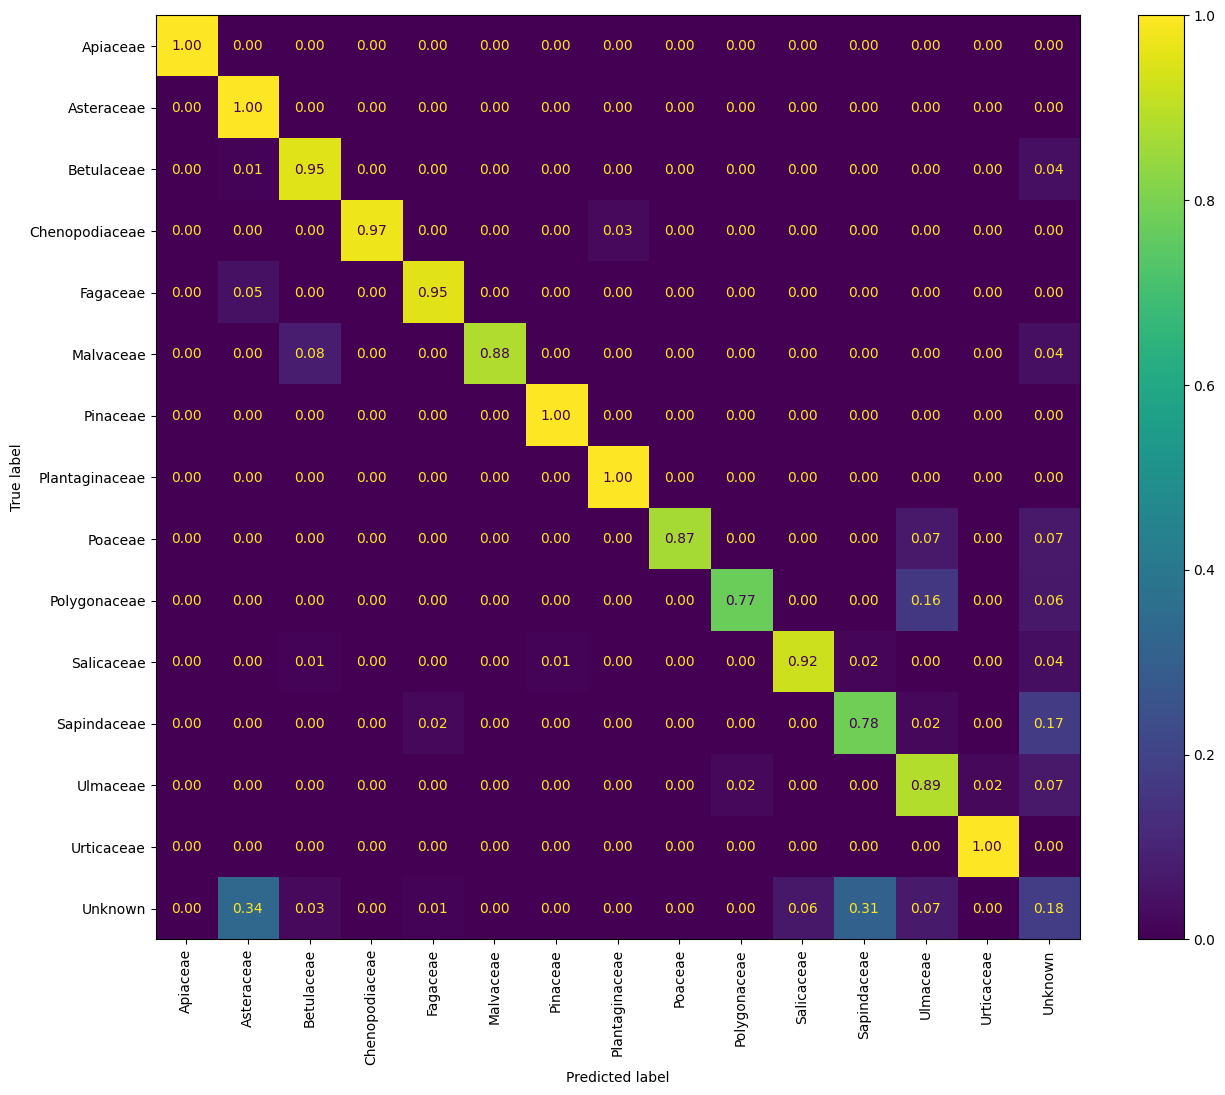

In [9]:
fig, ax = plt.subplots(figsize=(15,12))
cm = confusion_matrix(model_prediction_df["familia_label"], model_prediction_df["familia_prediction"], labels=possible_familia_labels)
disp = ConfusionMatrixDisplay.from_predictions(
    model_prediction_df["familia_label"], 
    model_prediction_df["familia_prediction"], 
    labels=possible_familia_labels, 
    display_labels=possible_familia_labels,
    xticks_rotation="vertical",
    normalize="true",
    values_format=".2f",
    ax=ax)
plt.savefig("Save/images/confusion_matrix_reference_familia_ds.svg")

In [10]:
print(classification_report(model_prediction_df["familia_label"], model_prediction_df["familia_prediction"], labels=possible_familia_labels))

                precision    recall  f1-score   support

      Apiaceae       1.00      1.00      1.00        34
    Asteraceae       0.65      1.00      0.79        74
    Betulaceae       0.95      0.95      0.95       120
Chenopodiaceae       1.00      0.97      0.99        38
      Fagaceae       0.91      0.95      0.93        22
     Malvaceae       1.00      0.88      0.94        25
      Pinaceae       0.97      1.00      0.99        39
Plantaginaceae       0.91      1.00      0.95        10
       Poaceae       1.00      0.87      0.93        15
  Polygonaceae       0.96      0.77      0.86        31
    Salicaceae       0.93      0.92      0.93       106
   Sapindaceae       0.50      0.78      0.61        46
      Ulmaceae       0.72      0.89      0.80        44
    Urticaceae       0.98      1.00      0.99        55
       Unknown       0.45      0.18      0.26       110

      accuracy                           0.83       769
     macro avg       0.86      0.88      0.86 

## Quality on Order level

In [11]:
label_to_ordo = { v: k for k, l in species_by_ordo.items() for v in l }
label_to_ordo["Unknown"] = "Unknown"
label_to_ordo

{'Acer': 'Sapindales',
 'Alnus': 'Fagales',
 'Betula': 'Fagales',
 'Corylus': 'Fagales',
 'Quercus': 'Fagales',
 'Ulmus': 'Rosales',
 'Malus': 'Rosales',
 'Urtica': 'Rosales',
 'Salix': 'Malpighiales',
 'Populus tremula': 'Malpighiales',
 'Tilia': 'Malvales',
 'Pinus': 'Pinales',
 'Picea': 'Pinales',
 'Apiaceae': 'Apiales',
 'Artemisia': 'Asterales',
 'Ambrosia': 'Asterales',
 'Taraxacum': 'Asterales',
 'Poaceae': 'Poales',
 'Chenopodiaceae': 'Caryophyllales',
 'Rumex': 'Caryophyllales',
 'Plantago': 'Lamiales',
 'Unknown': 'Unknown'}

In [12]:
model_prediction_df["ordo_label"] = model_prediction_df["label"].map(lambda x: label_to_ordo[x])
model_prediction_df["ordo_prediction"] = model_prediction_df["prediction"].map(lambda x: label_to_ordo[x])
model_prediction_df

,label,prediction,embeddings,image,familia_label,familia_prediction,ordo_label,ordo_prediction
0,Acer,Unknown,[ 1.7415385 0.3334825 -0.03600454 -0.572933...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Unknown,Sapindales,Unknown
1,Acer,Ulmus,[ 1.5100751 -0.15566942 0.4809177 0.910175...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Ulmaceae,Sapindales,Rosales
2,Acer,Unknown,[ 3.7482874 -0.74534714 -0.34647214 0.586683...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Unknown,Sapindales,Unknown
3,Acer,Unknown,[ 2.1391215 0.364511 0.16875696 2.004651...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Unknown,Sapindales,Unknown
4,Acer,Acer,[ 6.2565627 0.39929396 -0.13376594 -0.538832...,Dataset/pollen_dataset_2025_02_05\samples/Acer...,Sapindaceae,Sapindaceae,Sapindales,Sapindales
...,...,...,...,...,...,...,...,...
764,Unknown,Salix,[ 4.044817 0.94807583 -0.43934408 -0.880034...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Salicaceae,Unknown,Malpighiales
765,Unknown,Acer,[ 4.663302 -0.58977324 -0.06809011 -0.463438...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae,Unknown,Sapindales
766,Unknown,Acer,[ 3.9824102 1.8363025 0.7037991 -0.816554...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Sapindaceae,Unknown,Sapindales
767,Unknown,Salix,[ 5.4909763e+00 -1.2012720e-03 -1.2081781e-01 ...,Dataset/pollen_dataset_2025_02_05\samples/Malu...,Unknown,Salicaceae,Unknown,Malpighiales


In [13]:
possible_ordo_labels = list(set(pd.unique(model_prediction_df["ordo_label"])) | set(pd.unique(model_prediction_df["ordo_prediction"])))
possible_ordo_labels.sort()
possible_ordo_labels.append(possible_ordo_labels.pop(possible_ordo_labels.index("Unknown")))
possible_ordo_labels
possible_ordo_labels

['Apiales',
 'Asterales',
 'Caryophyllales',
 'Fagales',
 'Lamiales',
 'Malpighiales',
 'Malvales',
 'Pinales',
 'Poales',
 'Rosales',
 'Sapindales',
 'Unknown']

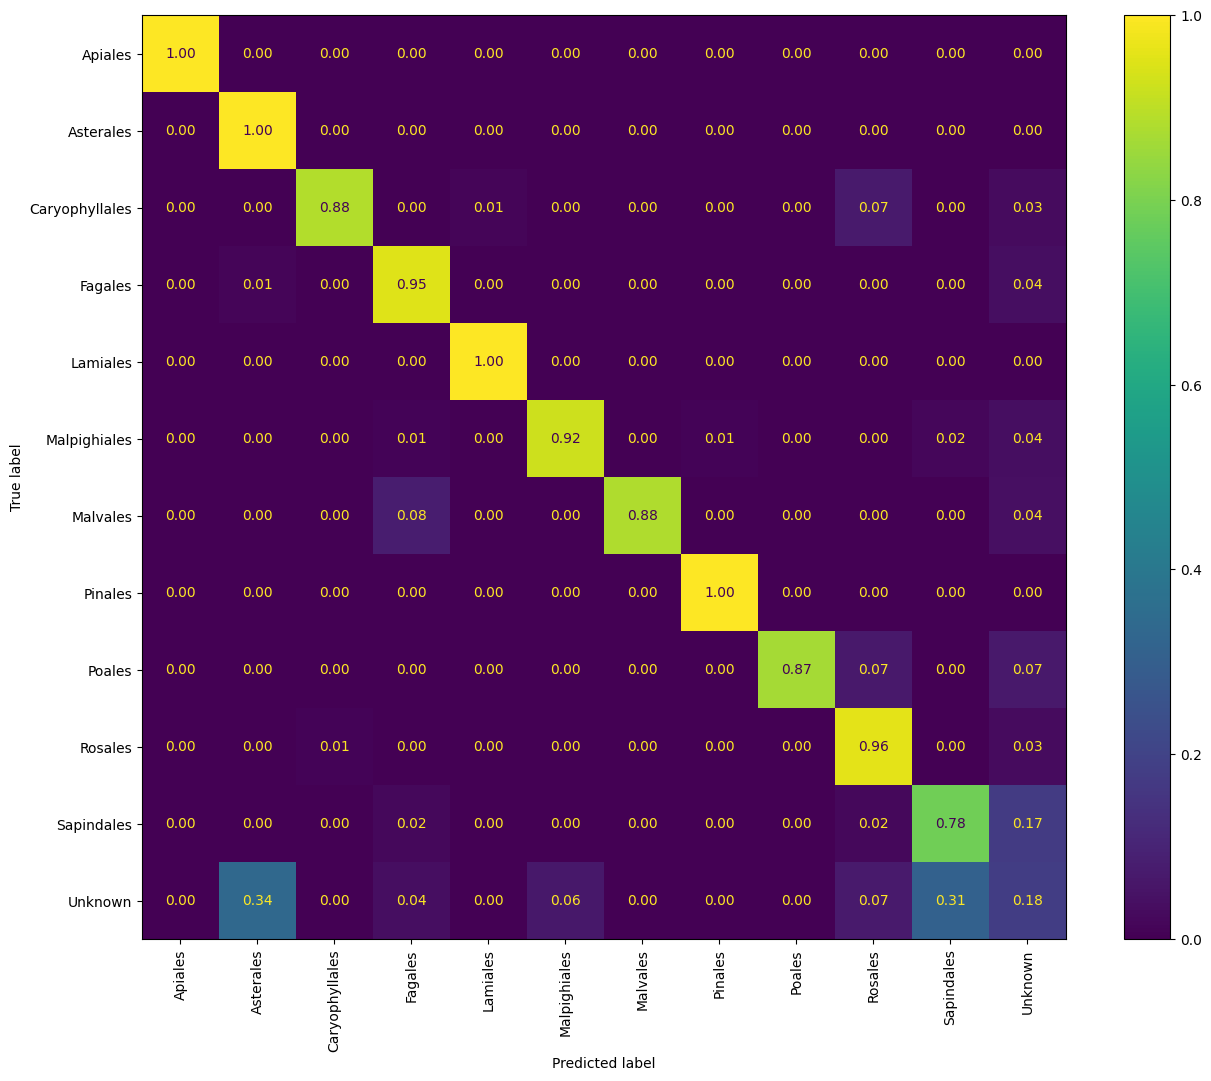

In [14]:
fig, ax = plt.subplots(figsize=(15,12))
cm = confusion_matrix(model_prediction_df["ordo_label"], model_prediction_df["ordo_prediction"], labels=possible_ordo_labels)
disp = ConfusionMatrixDisplay.from_predictions(
    model_prediction_df["ordo_label"], 
    model_prediction_df["ordo_prediction"], 
    labels=possible_ordo_labels, 
    display_labels=possible_ordo_labels,
    xticks_rotation="vertical",
    normalize="true",
    values_format=".2f",
    ax=ax)
plt.savefig("Save/images/confusion_matrix_reference_ordo_ds.svg")

In [15]:
print(classification_report(model_prediction_df["ordo_label"], model_prediction_df["ordo_prediction"], labels=possible_ordo_labels))

                precision    recall  f1-score   support

       Apiales       1.00      1.00      1.00        34
     Asterales       0.65      1.00      0.79        74
Caryophyllales       0.98      0.88      0.93        69
       Fagales       0.94      0.95      0.95       142
      Lamiales       0.91      1.00      0.95        10
  Malpighiales       0.93      0.92      0.93       106
      Malvales       1.00      0.88      0.94        25
       Pinales       0.97      1.00      0.99        39
        Poales       1.00      0.87      0.93        15
       Rosales       0.86      0.96      0.91        99
    Sapindales       0.50      0.78      0.61        46
       Unknown       0.45      0.18      0.26       110

      accuracy                           0.83       769
     macro avg       0.85      0.87      0.85       769
  weighted avg       0.82      0.83      0.81       769

